# Data Analyst Intern Assignment: Analyse User Engagement on an Online Learning Platform

In [ ]:
# Importing necessory libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Load the csv files
course_activity = pd.read_csv('course_activity.csv')
feedback = pd.read_csv('feedback.csv')
students = pd.read_csv('students.csv')

In [ ]:
# Display the first few rows of each dataset
print("\n Course Activity Data:\n")
print(course_activity.head())
print("\n Feedback Data:\n")
print(feedback.head())
print("\n Students Data:\n")
print(students.head())


 Course Activity Data:

  Student_ID Course_ID        Date  Time_Spent_Minutes  Completion_Percentage
0       S001     PY202  05/01/2024                  90                  46.10
1       S001     DM101  28/01/2024                 155                  88.87
2       S001     UX303  28/01/2024                 177                  54.93
3       S002     PY202  03/02/2024                  45                  32.20
4       S002     UX303  15/03/2024                 119                  90.80

 Feedback Data:

  Student_ID Course_ID  Rating       Feedback_Text
0       S057     UX303       2      Too fast-paced
1       S063     PY202       2  Loved the examples
2       S022     PY202       4     Could be better
3       S011     PY202       5   Needs improvement
4       S073     WD404       4     Could be better

 Students Data:

  Student_ID       Name  Age  Gender   Location Enrolment_Date
0       S001  Student_1   24  Female    Kolkata     24/11/2023
1       S002  Student_2   32   Other   

In [ ]:
# Bacis info of the data
print('\n `Course Activity` Data Info:\n')
print(course_activity.info())
print('\n `Feedback` Data Info:\n')
print(feedback.info())
print('\n `Students` Data Info:\n')
print(students.info())


 `Course Activity` Data Info:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 659 entries, 0 to 658
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Student_ID             659 non-null    object 
 1   Course_ID              659 non-null    object 
 2   Date                   659 non-null    object 
 3   Time_Spent_Minutes     659 non-null    int64  
 4   Completion_Percentage  659 non-null    float64
dtypes: float64(1), int64(1), object(3)
memory usage: 25.9+ KB
None

 `Feedback` Data Info:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Student_ID     80 non-null     object
 1   Course_ID      80 non-null     object
 2   Rating         80 non-null     int64 
 3   Feedback_Text  80 non-null     object
dtypes: int64(1), object(3)
memory usage: 2.6+ 

In [ ]:
# Identify and handle missing, duplicate, or inconsistent data
# Missing Values in course_activity, feedback, and students data
print('\n Missing Values in Course Activity Data:\n')
print(course_activity.isnull().sum())
print('\n Missing Values in Feedback Data:\n')
print(feedback.isnull().sum())
print('\n Missing Values in Students Data:\n')
print(students.isnull().sum())


 Missing Values in Course Activity Data:

Student_ID               0
Course_ID                0
Date                     0
Time_Spent_Minutes       0
Completion_Percentage    0
dtype: int64

 Missing Values in Feedback Data:

Student_ID       0
Course_ID        0
Rating           0
Feedback_Text    0
dtype: int64

 Missing Values in Students Data:

Student_ID        0
Name              0
Age               0
Gender            0
Location          0
Enrolment_Date    0
dtype: int64


In [ ]:
# Duplicate values in course_activity, feedback, and students data
print('\n Duplicate Values in Course Activity Data:\n')
print(course_activity.duplicated().sum())
print('\n Duplicate Values in Feedback Data:\n')
print(feedback.duplicated().sum())
print('\n Duplicate Values in Students Data:\n')
print(students.duplicated().sum())


 Duplicate Values in Course Activity Data:

0

 Duplicate Values in Feedback Data:

0

 Duplicate Values in Students Data:

0


In [ ]:
# descibe the data in the numeric
print('\nDescribed Course Activity Data:\n')
print(course_activity.describe())
print('\nDescribed Feedback Data:\n')
print(feedback.describe())
print('\nDescribed Students Data:\n')
print(students.describe())


Described Course Activity Data:

                                Date  Time_Spent_Minutes  \
count                            659          659.000000   
mean   2024-02-15 14:18:45.341426432           98.113809   
min              2024-01-01 00:00:00           10.000000   
25%              2024-01-24 00:00:00           58.000000   
50%              2024-02-17 00:00:00           98.000000   
75%              2024-03-10 00:00:00          139.000000   
max              2024-03-31 00:00:00          180.000000   
std                              NaN           49.045548   

       Completion_Percentage  
count             659.000000  
mean               54.778710  
min                10.150000  
25%                32.070000  
50%                53.450000  
75%                77.560000  
max               100.000000  
std                26.289156  

Described Feedback Data:

          Rating
count  80.000000
mean    2.962500
std     1.453444
min     1.000000
25%     2.000000
50%     3.000000


In [ ]:
# Convert data types where necessary (e.g., dates, numeric fields)
course_activity['Date'] = pd.to_datetime(course_activity['Date'], format='%d/%m/%Y')

In [ ]:
# What is the overall average completion rate across courses?
overall_completion_rate = course_activity['Completion_Percentage'].mean()
print(f"Overall Average Completion Rate: {overall_completion_rate:.2f}%")

Overall Average Completion Rate: 54.78%


In [ ]:
# Which course has the highest and lowest average engagement time?
course_engagement = course_activity.groupby('Course_ID')['Time_Spent_Minutes'].mean()
highest_engagement_course = course_engagement.idxmax()
lowest_engagement_course = course_engagement.idxmin()
print(f"Course with Highest Average Engagement: Course {highest_engagement_course}")
print(f"Course with Lowest Average Engagement: Course {lowest_engagement_course}")

Course with Highest Average Engagement: Course DM101
Course with Lowest Average Engagement: Course PY202


In [ ]:
# How does engagement differ by age group or location?
course_activity_merged = pd.merge(course_activity, students, on='Student_ID')
engagement_by_location = course_activity_merged.groupby('Location')['Time_Spent_Minutes'].mean()
engagement_by_age_group = course_activity_merged.groupby('Age')['Time_Spent_Minutes'].mean()
print("\nEngagement by Location:\n\n", engagement_by_location)
print("\nEngagement by Age Group:\n\n", engagement_by_age_group)


Engagement by Location:

 Location
Bangalore     98.000000
Chennai       90.946746
Delhi        103.302857
Kolkata      104.384615
Mumbai        95.435484
Name: Time_Spent_Minutes, dtype: float64

Engagement by Age Group:

 Age
18    107.102041
19    100.619048
20     92.051724
21    118.062500
22    104.464286
23     81.384615
24     95.137931
25    102.910714
26    105.405405
27     94.470588
28     94.137931
29     90.000000
30    101.578947
31    104.551724
32     94.746032
33     92.321429
34     84.727273
Name: Time_Spent_Minutes, dtype: float64


In [ ]:
#	What is the average feedback rating per course?
average_feedback_rating = feedback.groupby('Course_ID')['Rating'].mean()
print("\nAverage Feedback Rating per Course:\n\n", average_feedback_rating)


Average Feedback Rating per Course:

 Course_ID
DM101    2.900000
PY202    3.277778
UX303    2.923077
WD404    2.789474
Name: Rating, dtype: float64


In [ ]:
# Is there a correlation between completion rate and feedback rating?
correlation_completion_feedback = course_activity['Completion_Percentage'].corr(feedback['Rating'])
print(f'Correlation between completion rate and feedback rating: \n {correlation_completion_feedback}')

Correlation between completion rate and feedback rating: 
 -0.11629781325237766


In [ ]:
# Identify top 3 student segments based on engagement and satisfaction.
student_engagement = course_activity.groupby('Student_ID')['Time_Spent_Minutes'].sum()
student_satisfaction = feedback.groupby('Student_ID')['Rating'].mean()
top_3_segments = student_engagement.nlargest(3).index.tolist() + student_satisfaction.nlargest(3).index.tolist()
print("\nTop 3 Student Segments based on Engagement and Satisfaction:\n\n", top_3_segments)



Top 3 Student Segments based on Engagement and Satisfaction:

 ['S042', 'S024', 'S066', 'S011', 'S017', 'S036']


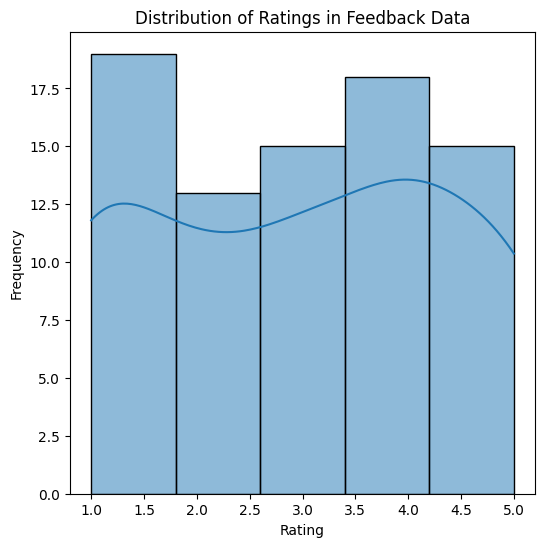

In [ ]:
# Distribution of Ratings in Feedback Data
plt.figure(figsize=(6, 6))
sns.histplot(feedback['Rating'], bins=5, kde=True)
plt.title('Distribution of Ratings in Feedback Data')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.show()

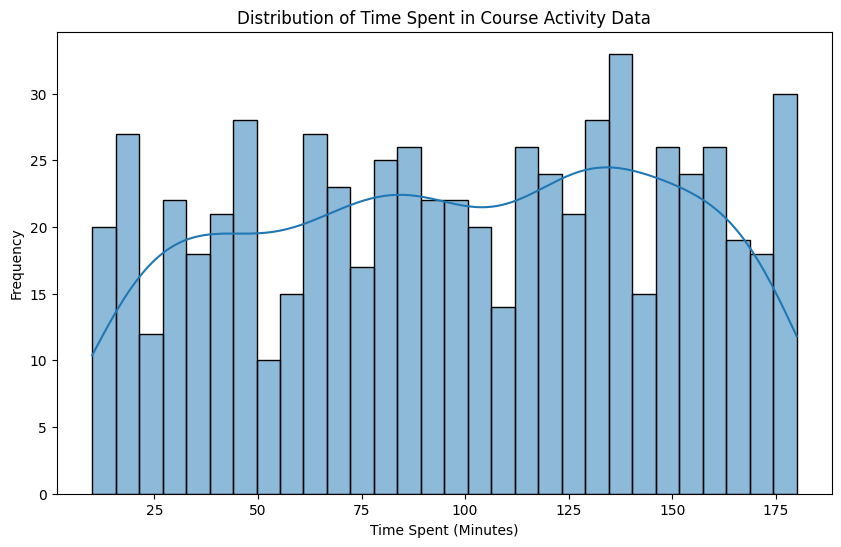

In [ ]:
# Distribution of Time Spent in Course Activity Data
plt.figure(figsize=(10, 6))
sns.histplot(course_activity['Time_Spent_Minutes'], bins=30, kde=True)
plt.title('Distribution of Time Spent in Course Activity Data')
plt.xlabel('Time Spent (Minutes)')
plt.ylabel('Frequency')
plt.show()

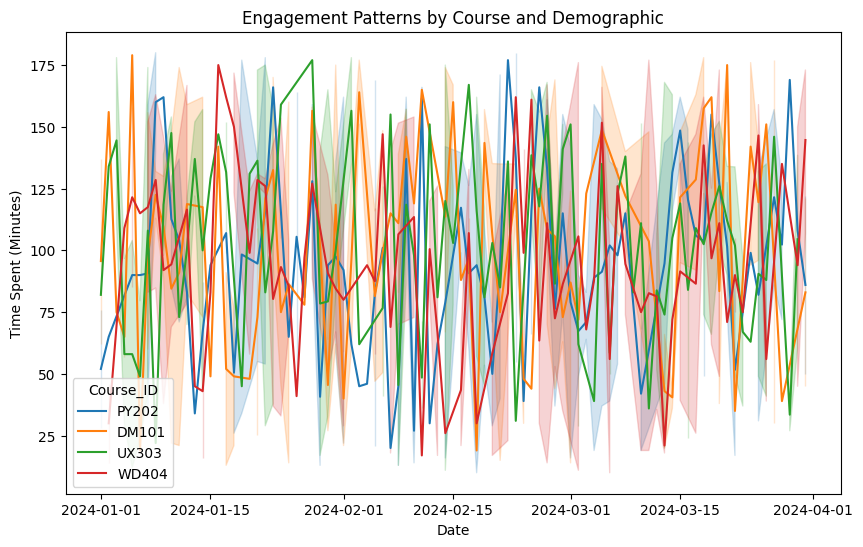

In [ ]:
# Show engagement patterns by course and demographic
plt.figure(figsize = (10, 6))
sns.lineplot(x = 'Date', y = 'Time_Spent_Minutes', hue = 'Course_ID', data = course_activity)
plt.title('Engagement Patterns by Course and Demographic')
plt.xlabel('Date')
plt.ylabel('Time Spent (Minutes)')
plt.show()

In [ ]:
# Merging Data for Comprehensive Analysis
merged_data = pd.merge(feedback, students, on='Student_ID', how='inner')
print("\nMerged Data Sample:")
print(merged_data.head())


Merged Data Sample:
  Student_ID Course_ID  Rating       Feedback_Text        Name  Age  Gender  \
0       S057     UX303       2      Too fast-paced  Student_57   25   Other   
1       S063     PY202       2  Loved the examples  Student_63   32  Female   
2       S022     PY202       4     Could be better  Student_22   32    Male   
3       S011     PY202       5   Needs improvement  Student_11   19  Female   
4       S073     WD404       4     Could be better  Student_73   25   Other   

    Location Enrolment_Date  
0      Delhi     18/11/2023  
1     Mumbai     05/02/2023  
2      Delhi     15/10/2023  
3    Chennai     14/02/2023  
4  Bangalore     21/08/2023  


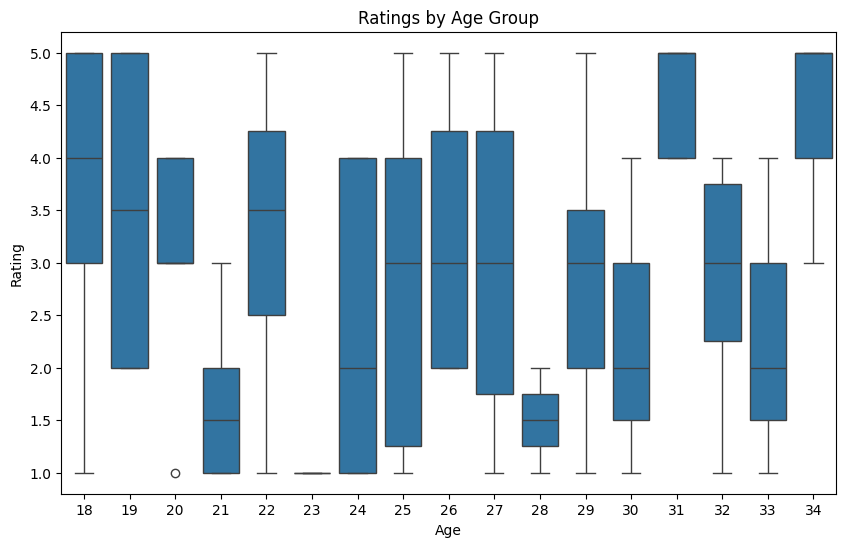

In [ ]:
# Analyzing Ratings by Age Group scatter plot
plt.figure(figsize=(10, 6))
sns.boxplot(x='Age', y='Rating', data=merged_data)
plt.title('Ratings by Age Group')
plt.xlabel('Age')
plt.ylabel('Rating')
plt.show()

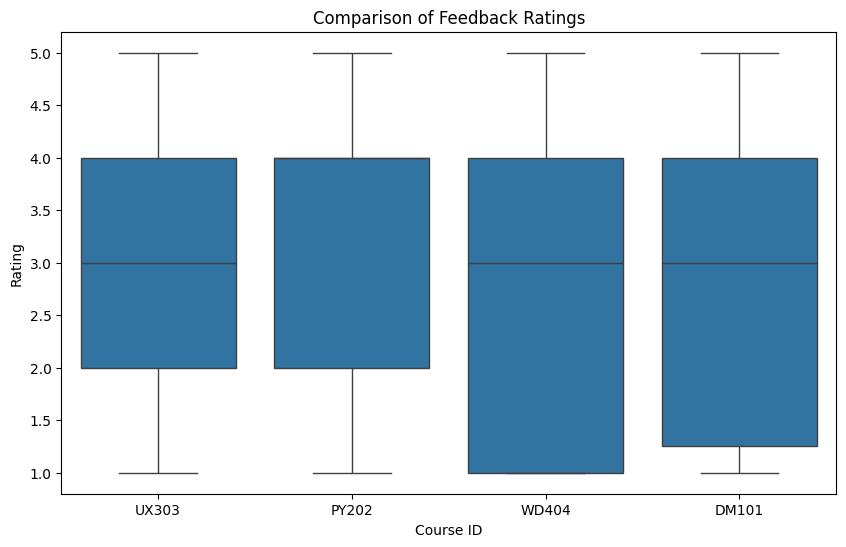

In [ ]:
# Compare feedback ratings
plt.figure(figsize=(10, 6))
sns.boxplot(x='Course_ID', y='Rating', data=feedback)
plt.title('Comparison of Feedback Ratings')
plt.xlabel('Course ID')
plt.ylabel('Rating')
plt.show()

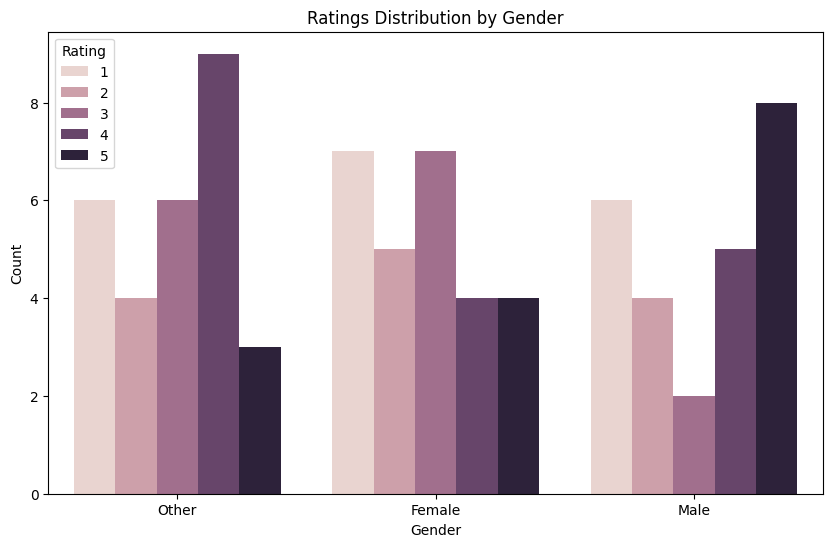

In [ ]:
# Analyzing Ratings by Gender scatter plot

plt.figure(figsize=(10, 6))
sns.countplot(x='Gender', hue='Rating', data=merged_data)
plt.title('Ratings Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

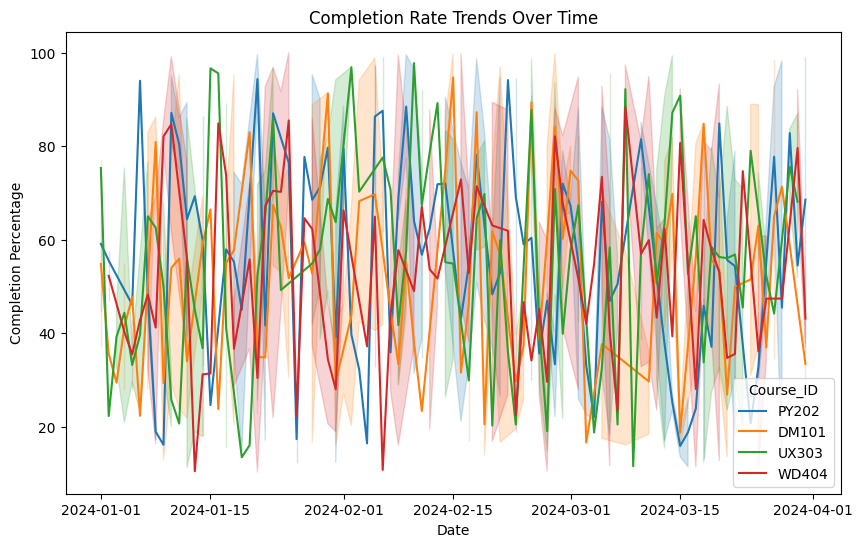

In [ ]:
# Highlight trends over time
plt.figure(figsize=(10, 6))
sns.lineplot(x='Date', y='Completion_Percentage', hue='Course_ID', data=course_activity)
plt.title('Completion Rate Trends Over Time')
plt.xlabel('Date')
plt.ylabel('Completion Percentage')
plt.show()